# Preliminary tests w/ MINT

A notebook for playing with the MINT package.

https://github.com/jchoi55/MINT

### Preamble

In [26]:
import numpy as np
import mint
from matplotlib import pyplot as plt

In [6]:
# See available lattice configurations
print(mint.lattices.available())

{'mc_10tev_hybrid_v06': '10 TeV muon collider interaction region, hybrid IR design v06 (MAD-X twiss: ir1ccma_hybrid_v06; covers ~1.5 km of the 10 km ring)', 'mc_10tev_IR_v09': '10 TeV muon collider interaction region only, v09 (sublattice of the 10 km ring)', 'mc_10tev_ring_v06': '10 TeV muon collider, the FULL 8.7 km ring, design v06 (arcs included, so no total_circumference override is needed)', 'mc_3tev_v1.2': '3 TeV muon collider, the full 4.3 km ring, design v1.2 (1.5 TeV per beam)'}


### [1.] 10 TeV muon collider interaction region, hybrid IR design v.06

In [8]:
# Load collider ring lattice
ring1 = mint.lattices.load("mc_10tev_hybrid_v06")

In [12]:
# Simulate muon decays along ring
sim1 = mint.MuDecaySimulator(muon_polarization=0.0, lattice=ring1, nuflavor='numubar', n_evals=1e5, beam_dynamics=True)
sim1.decay_muons()
sim1.place_muons_on_lattice(lattice=ring1, direction='clockwise')

/Users/criggall/Documents/neutrino-corridor/.venv/lib/python3.14/site-packages/mint/MuC.py:491: UserWarning: The lattice covers only 14.6% of the machine (arc length 1.465e+05 cm of total_circumference 1e+06 cm). Muon decays are placed on the covered section only; muon travel times account for propagation through the full machine.
  warnings.warn(


In [ ]:
# Neutrino flux through detector face 1 km downstream of IP
E1, flux1 = sim1.get_flux_at_generic_location(
    det_location=[0, 0, 1e5], # cm
    det_radius=2e2, # cm
    ebins=np.linspace(0, 5e3, 31)
)

In [41]:
E1

array([   0.        ,  166.66666667,  333.33333333,  500.        ,
        666.66666667,  833.33333333, 1000.        , 1166.66666667,
       1333.33333333, 1500.        , 1666.66666667, 1833.33333333,
       2000.        , 2166.66666667, 2333.33333333, 2500.        ,
       2666.66666667, 2833.33333333, 3000.        , 3166.66666667,
       3333.33333333, 3500.        , 3666.66666667, 3833.33333333,
       4000.        , 4166.66666667, 4333.33333333, 4500.        ,
       4666.66666667, 4833.33333333, 5000.        ])

In [42]:
flux1

array([0.06029554, 0.05963658, 0.06230884, 0.05985455, 0.05594453,
       0.05589867, 0.05854637, 0.05375832, 0.05422738, 0.05245389,
       0.04939257, 0.04780735, 0.04462859, 0.04042729, 0.04200177,
       0.03656385, 0.03516505, 0.03260532, 0.03069182, 0.02807482,
       0.02439852, 0.02165646, 0.01944394, 0.01596918, 0.01447026,
       0.01169665, 0.00888915, 0.0051177 , 0.00389213, 0.00120654])

In [43]:
print(len(E1))
print(len(flux1))

31
30


^ If flux is neutrino flux for given energy bin, why are the flux and E arrays not the same length? (From testing, flux is always 1 entry shorter than E)

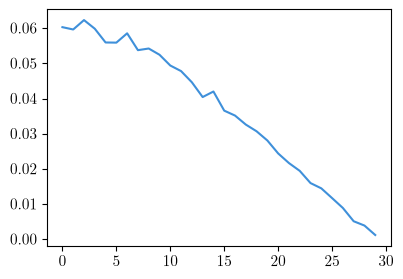

In [63]:
plt.plot(flux1);

In [44]:
sum(flux1)

np.float64(1.0870236247189498)

^ Also why is the sum more than 1?

### [2.] 10 TeV muon collider interaction region, v.09

In [45]:
# Load collider ring lattice
ring2 = mint.lattices.load("mc_10tev_IR_v09")

In [46]:
# Simulate muon decays along ring
sim2 = mint.MuDecaySimulator(muon_polarization=0.0, lattice=ring2, nuflavor='numubar', n_evals=1e5, beam_dynamics=True)
sim2.decay_muons()
sim2.place_muons_on_lattice(lattice=ring2, direction='clockwise')

/Users/criggall/Documents/neutrino-corridor/.venv/lib/python3.14/site-packages/mint/MuC.py:491: UserWarning: The lattice covers only 3.6% of the machine (arc length 3.645e+04 cm of total_circumference 1e+06 cm). Muon decays are placed on the covered section only; muon travel times account for propagation through the full machine.
  warnings.warn(


In [47]:
# Neutrino flux through detector face 1 km downstream of IP
E2, flux2 = sim2.get_flux_at_generic_location(
    det_location=[0, 0, 1e5], # cm
    det_radius=2e2, # cm
    ebins=np.linspace(0, 5e3, 31)
)

In [48]:
E2

array([   0.        ,  166.66666667,  333.33333333,  500.        ,
        666.66666667,  833.33333333, 1000.        , 1166.66666667,
       1333.33333333, 1500.        , 1666.66666667, 1833.33333333,
       2000.        , 2166.66666667, 2333.33333333, 2500.        ,
       2666.66666667, 2833.33333333, 3000.        , 3166.66666667,
       3333.33333333, 3500.        , 3666.66666667, 3833.33333333,
       4000.        , 4166.66666667, 4333.33333333, 4500.        ,
       4666.66666667, 4833.33333333, 5000.        ])

In [49]:
flux2

array([0.05876087, 0.05909532, 0.05842083, 0.05763945, 0.05623583,
       0.05544509, 0.05464196, 0.05294973, 0.05140374, 0.049219  ,
       0.04839773, 0.04588406, 0.04381141, 0.04200359, 0.03928801,
       0.03708773, 0.03463325, 0.0324942 , 0.02979085, 0.02750731,
       0.02383592, 0.0221304 , 0.01890702, 0.01644598, 0.01408833,
       0.01133111, 0.00852265, 0.00610033, 0.00354449, 0.0011539 ])

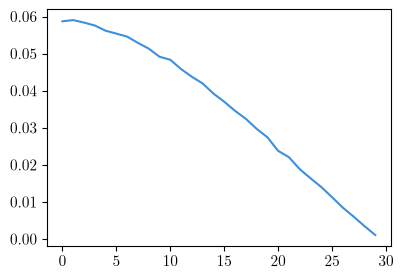

In [65]:
plt.plot(flux2);

In [50]:
flux1 == flux2

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

^ Confirmation that lattice does (in some way) affect the flux calculation

In [51]:
# Neutrino flux through detector face 9.253 km downstream of IP
E2_2, flux2_2 = sim2.get_flux_at_generic_location(
    det_location=[0, 0, 9.253e5], # cm
    det_radius=2e2, # cm
    ebins=np.linspace(0, 5e3, 31)
)

In [58]:
flux2_2

array([0.02108492, 0.0282201 , 0.02753532, 0.02798903, 0.02820673,
       0.0267185 , 0.02699486, 0.02545265, 0.02487122, 0.02470246,
       0.02329518, 0.02349629, 0.02151403, 0.02040475, 0.01907167,
       0.01837991, 0.01725256, 0.01594846, 0.01500513, 0.01326349,
       0.01173474, 0.01033902, 0.00949193, 0.00815456, 0.00659272,
       0.00536173, 0.00393429, 0.00285079, 0.00171785, 0.00066708])

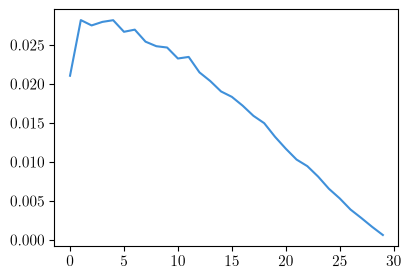

In [66]:
plt.plot(flux2_2);